In [25]:
%matplotlib inline
# %matplotlib qt
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns, valid_observatory_names
from astropy.time import Time
import matplotlib
from astropy.coordinates import SkyCoord

In [26]:
print(valid_observatory_names)

['MAGIC', 'MAGIC-LST', 'MAGIC-4LST', 'VERITAS', 'MAGIC-4LST-microstars', 'CTA-N', 'CTA-N_alpha', 'MAGIC-CTA-N', 'CTA-N-LSTs', 'CTA-S', 'CTA-S_alpha', 'CTA-S_alpha_2LSTs', 'CTA-N_alpha_phase_II', 'CTA-S_alpha_2LSTs_phase_II', 'CTA-S_alpha_phase_II', 'MAGIC-butterfleye', 'MAGIC2-facets-butterfleye', 'MAGIC-4LST-butterfleye', 'MAGIC-CTA-N-butterfleye', '4LST', '4LST-butterfleye']


In [27]:
sim_run = SimulateSiiRuns("gam Crv", zbc_norm=1., observatory_name="CTA-N-LSTs")
sim_run.target_b_mag

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


2.48

In [28]:
times = ['2021-07-01T21:00:00', 
         '2021-07-01T22:00:00',
         '2021-07-01T23:00:00',]
time_array = Time(times, format='isot', scale='utc')
zbc_times = ['2021-07-01T22:30:00', 
             '2021-07-01T23:30:00']
zbc_time_array = Time(zbc_times, format='isot', scale='utc')

In [29]:
sim_run.simulate_observations(time_array, run_duration=10*u.min)
# We can also assume zero-baseline correlation measurements are performed with that same star (assuming chess-board mode)
sim_run.simulate_zbc_observations(zbc_time_array, run_duration=10*u.min)

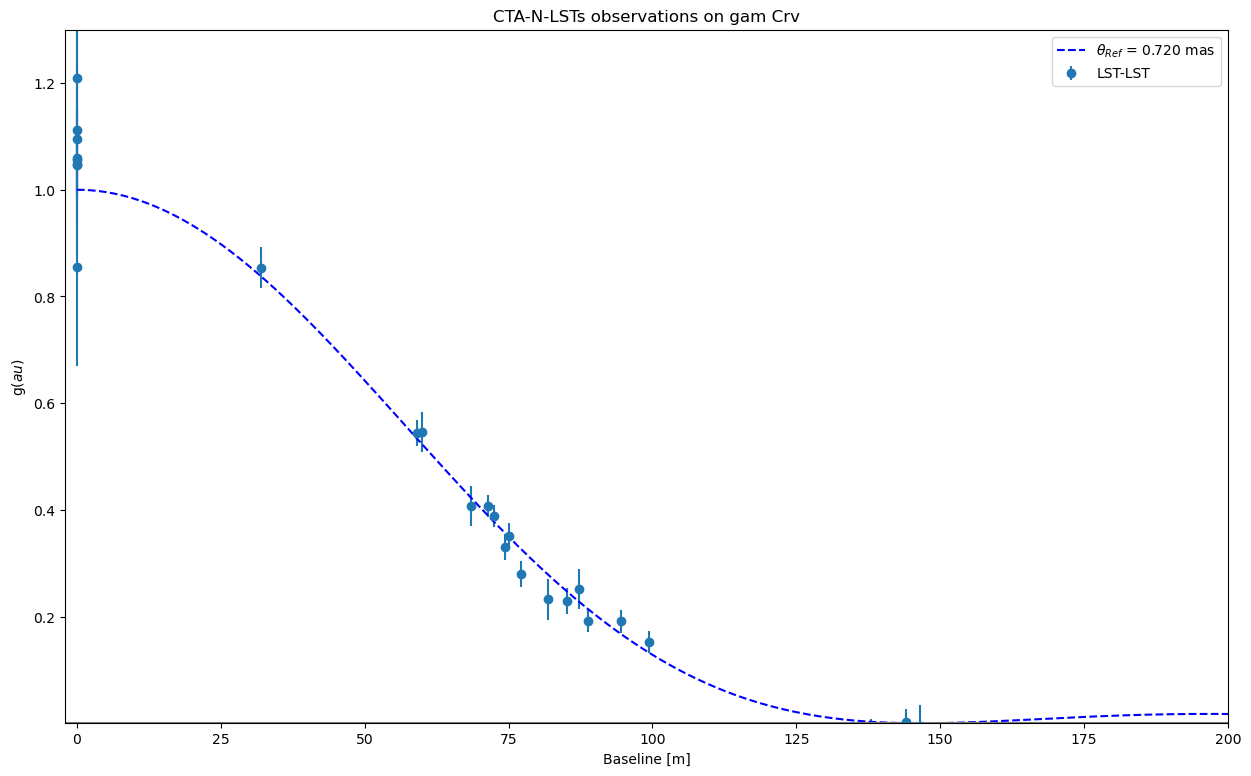

In [30]:
sim_run.plot_v2(set_log_yscale=False)
sim_run.f.savefig("test.png")

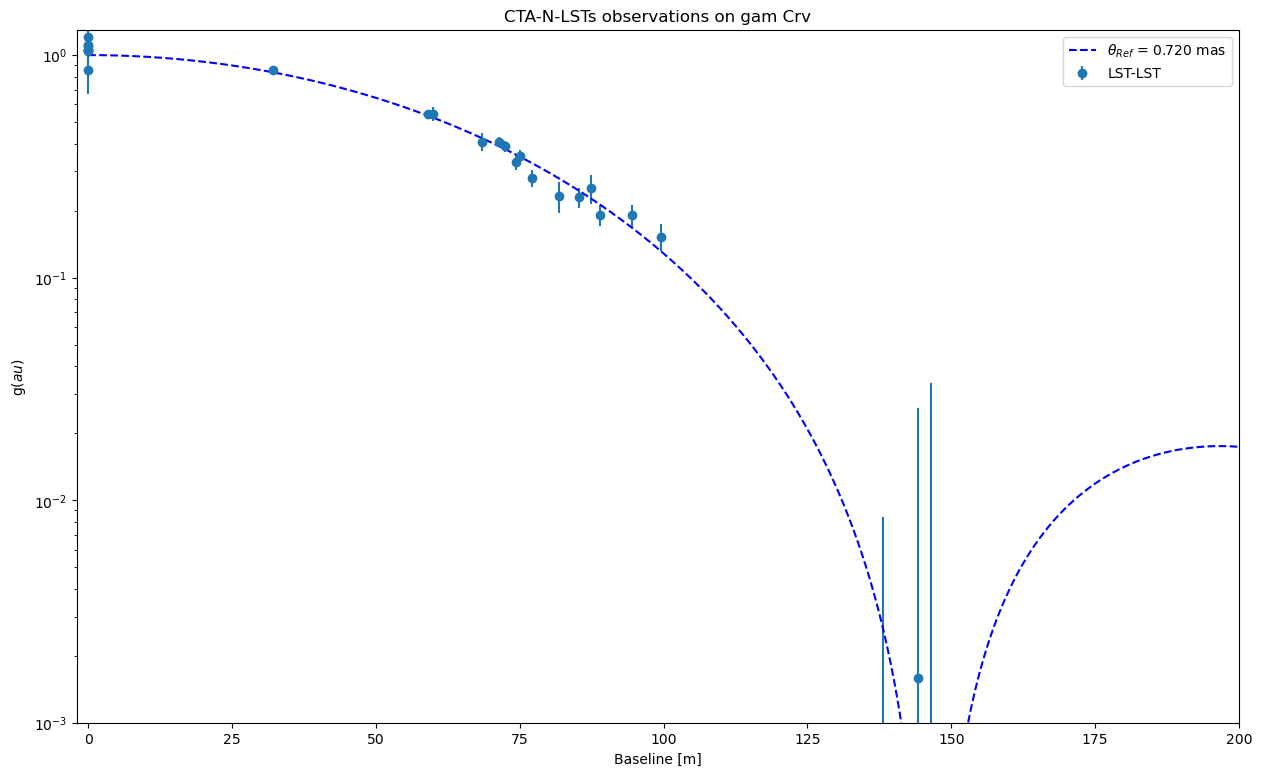

In [31]:
sim_run.plot_v2()

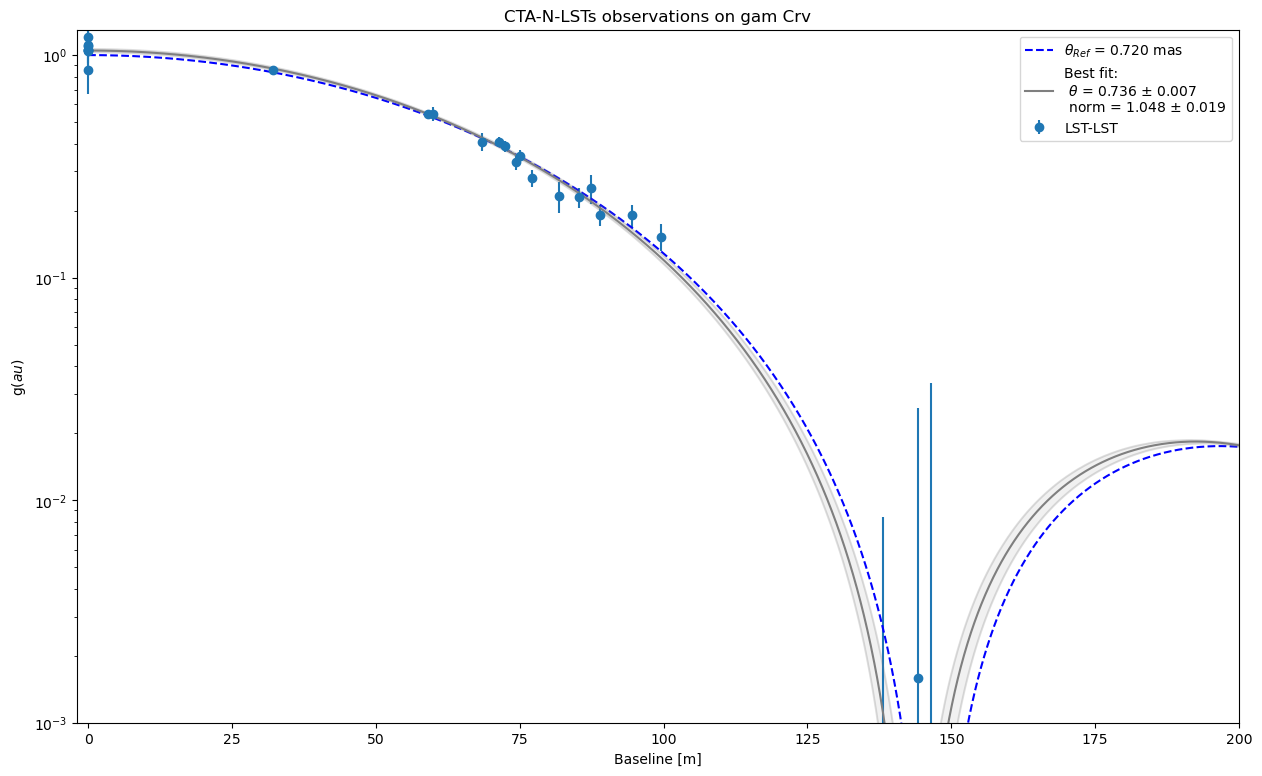

In [32]:
sim_run.fit_uniform_disc()
sim_run.plot_v2()

In [33]:
n_simulations = 50
times = ['2021-07-01T22:00:00', 
     '2021-07-01T23:00:00', 
     '2021-07-02T00:00:00', 
     '2021-07-02T01:00:00', 
     '2021-07-02T02:00:00', 
     '2021-07-02T03:00:00', 
     '2021-07-02T04:00:00']
time_array = Time(times, format='isot', scale='utc')

fit_norms = []
fit_theta = []
sim_run = SimulateSiiRuns("eta UMa", zbc_norm=1., observatory_name="CTA-N-LSTs")
for i in np.arange(0, n_simulations, 1):
    if i%10 == 0:
        print("{}/{}".format(i, n_simulations))
    sim_run.simulate_observations(time_array, run_duration=10*u.min, fast_simulation=True)
    sim_run.fit_uniform_disc()
    fit_results = sim_run.uniform_disc_fit
    fit_theta.append(fit_results['theta'])
    fit_norms.append(fit_results['norm'])
    sim_run.reset()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (206.88515734, 49.31326673)>
Closest star found within the JMDC is:
 -Star ids: HD120315 or eta UMa
- Stellar diameter: 0.937
0/50
10/50
20/50
30/50
40/50


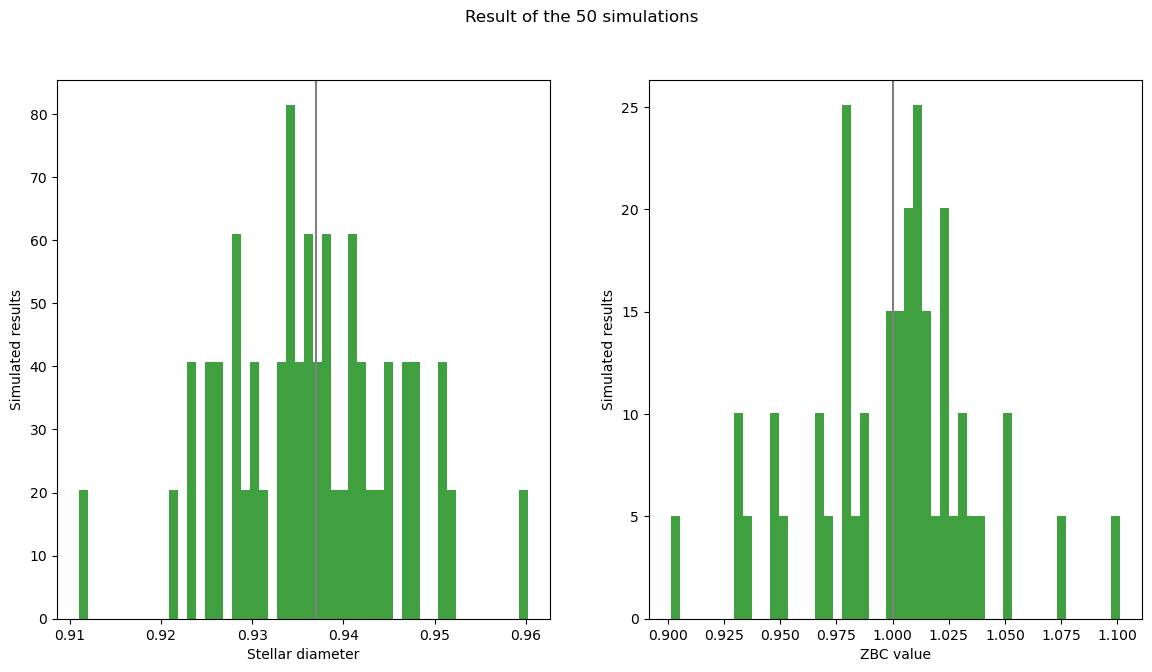

In [34]:
# the histogram of the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14, 7])
fig.suptitle('Result of the {} simulations'.format(n_simulations))
ax1.hist(fit_theta, 50, density=True, facecolor='g', alpha=0.75)
ax1.axvline(x=sim_run.stellar_diameter.to('mas').value, color='grey', linestyle='-')
ax1.yaxis.set_label_text('Simulated results')
ax1.xaxis.set_label_text('Stellar diameter')

ax2.hist(fit_norms, 50, density=True, facecolor='g', alpha=0.75)
ax2.axvline(x=sim_run.zbc_norm, color='grey', linestyle='-')
ax2.yaxis.set_label_text('Simulated results')
ax2.xaxis.set_label_text('ZBC value')
plt.show()


In [37]:
n_simulations = 50
times = ['2021-07-01T22:00:00', 
     '2021-07-01T23:00:00', 
     '2021-07-02T00:00:00', 
     '2021-07-02T01:00:00', 
     '2021-07-02T02:00:00', 
     '2021-07-02T03:00:00', 
     '2021-07-02T04:00:00']
time_array = Time(times, format='isot', scale='utc')

fit_norms = []
fit_theta = []
sim_run = SimulateSiiRuns("eta UMa", zbc_norm=1., observatory_name="CTA-N_alpha")
for i in np.arange(0, n_simulations, 1):
    if i%10 == 0:
        print("{}/{}".format(i, n_simulations))
    sim_run.simulate_observations(time_array, run_duration=10*u.min, fast_simulation=True)
    sim_run.fit_uniform_disc()
    fit_results = sim_run.uniform_disc_fit
    fit_theta.append(fit_results['theta'])
    fit_norms.append(fit_results['norm'])
    sim_run.reset()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (206.88515734, 49.31326673)>
Closest star found within the JMDC is:
 -Star ids: HD120315 or eta UMa
- Stellar diameter: 0.937
0/50
10/50
20/50
30/50
40/50


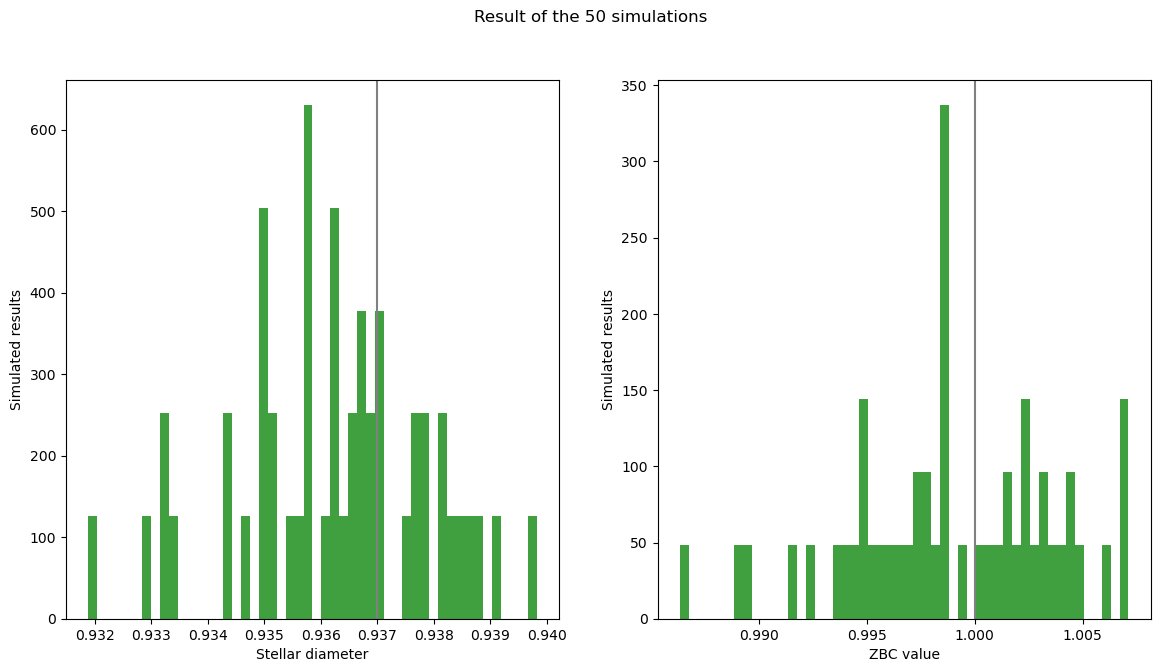

In [38]:
# the histogram of the data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[14, 7])
fig.suptitle('Result of the {} simulations'.format(n_simulations))
ax1.hist(fit_theta, 50, density=True, facecolor='g', alpha=0.75)
ax1.axvline(x=sim_run.stellar_diameter.to('mas').value, color='grey', linestyle='-')
ax1.yaxis.set_label_text('Simulated results')
ax1.xaxis.set_label_text('Stellar diameter')

ax2.hist(fit_norms, 50, density=True, facecolor='g', alpha=0.75)
ax2.axvline(x=sim_run.zbc_norm, color='grey', linestyle='-')
ax2.yaxis.set_label_text('Simulated results')
ax2.xaxis.set_label_text('ZBC value')
plt.show()
